In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
#

#Loading the Dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving HO recruitment exercise data 2026.xlsx to HO recruitment exercise data 2026.xlsx


In [ ]:
## Inspecting the dataset
excel = pd.ExcelFile("HO recruitment exercise data 2026.xlsx")

print(excel.sheet_names)

['Data Dictionary', 'Data']


In [ ]:
## loading the data sheet
hor = pd.read_excel(excel, sheet_name="Data")
#

# Exploratory Data Analysis (EDA)

In [ ]:
## Data inspection

In [ ]:
hor.head()

,Company Reference,Company Type,Postcode,CompanyCategory,CompanyStatus,CountryOfOrigin,Company Closed Date,IncorporationDate,AccountLastMadeDate,2022 Turnover,2023 Turnover,2024 Turnover,2025 Turnover,2026 Turnover
0,Summary-Construction,Construction,All,All,NaN,NaN,NaT,NaT,NaT,3.760266e+09,4.177156e+09,4.623585e+09,4.805016e+09,4.758252e+09
1,Summary-Consultancy,Consultancy,All,All,NaN,NaN,NaT,NaT,NaT,4.149473e+09,3.280256e+09,5.162926e+09,5.400981e+09,5.403103e+09
2,Summary-Education,Education,All,All,NaN,NaN,NaT,NaT,NaT,2.479188e+08,2.476784e+08,2.464316e+08,2.163052e+08,1.829862e+08
3,Summary-Farming,Farming,All,All,NaN,NaN,NaT,NaT,NaT,2.189388e+08,2.059912e+08,2.037192e+08,2.200120e+08,2.053459e+08
4,Summary-Healthcare,Healthcare,All,All,NaN,NaN,NaT,NaT,NaT,5.469332e+08,6.657067e+08,8.184443e+08,9.425471e+08,1.037401e+09


In [ ]:
hor.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50520 entries, 0 to 50519
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Company Reference    50520 non-null  object        
 1   Company Type         50495 non-null  object        
 2   Postcode             49884 non-null  object        
 3   CompanyCategory      50520 non-null  object        
 4   CompanyStatus        50510 non-null  object        
 5   CountryOfOrigin      50510 non-null  object        
 6   Company Closed Date  918 non-null    datetime64[ns]
 7   IncorporationDate    50510 non-null  datetime64[ns]
 8   AccountLastMadeDate  37315 non-null  datetime64[ns]
 9   2022 Turnover        28981 non-null  float64       
 10  2023 Turnover        32321 non-null  float64       
 11  2024 Turnover        35880 non-null  float64       
 12  2025 Turnover        37188 non-null  float64       
 13  2026 Turnover        37171 non-

In [ ]:
hor.shape

(50520, 14)

In [ ]:
hor.columns

Index(['Company Reference', 'Company Type', 'Postcode', 'CompanyCategory',
       'CompanyStatus', 'CountryOfOrigin', 'Company Closed Date',
       'IncorporationDate', 'AccountLastMadeDate', '2022 Turnover',
       '2023 Turnover', '2024 Turnover', '2025 Turnover', '2026 Turnover'],
      dtype='object')

In [ ]:
hor.describe()

,Company Closed Date,IncorporationDate,AccountLastMadeDate,2022 Turnover,2023 Turnover,2024 Turnover,2025 Turnover,2026 Turnover
count,918,50510,37315,2.898100e+04,3.232100e+04,3.588000e+04,3.718800e+04,3.717100e+04
mean,2017-05-25 21:45:05.882352896,2015-09-24 17:04:21.857058048,2023-06-04 17:37:54.999330304,1.548349e+06,1.208095e+06,1.295278e+06,1.432911e+06,1.491657e+06
min,1983-07-05 00:00:00,1870-09-12 00:00:00,1983-03-31 00:00:00,2.590300e+04,2.287400e+04,2.774900e+04,2.168600e+04,2.214200e+04
25%,2017-01-24 06:00:00,2012-11-14 00:00:00,2023-04-30 00:00:00,4.738570e+05,2.934810e+05,2.935158e+05,3.661940e+05,4.229000e+05
50%,2021-08-19 00:00:00,2019-05-20 00:00:00,2023-09-30 00:00:00,5.411850e+05,3.406190e+05,3.403610e+05,4.508315e+05,5.259500e+05
75%,2023-04-13 18:00:00,2023-01-18 00:00:00,2024-01-31 00:00:00,6.197350e+05,7.052540e+05,5.955360e+05,6.836202e+05,6.288510e+05
max,2024-12-26 00:00:00,2026-06-23 00:00:00,2024-12-22 00:00:00,9.473820e+09,6.550253e+09,7.291541e+09,9.680920e+09,1.127710e+10
std,NaN,NaN,NaN,6.606926e+07,4.914603e+07,5.523301e+07,6.488628e+07,7.107124e+07


## checking Data quality


Missing values were assessed across all variables to understand their potential impact on the analysis. Large numbers of missing values were observed in the Company Closed Date column; however, these are expected for active companies and were retained. Missing turnover values will be considered when analysing financial performance, while variables with only a small number of missing values will be handled on a case-by-case basis depending on their relevance to each business question.

In [ ]:
hor.isnull().sum().sort_values(ascending=False)

,0
Company Closed Date,49602
2022 Turnover,21539
2023 Turnover,18199
2024 Turnover,14640
2026 Turnover,13349
2025 Turnover,13332
AccountLastMadeDate,13205
Postcode,636
Company Type,25
CountryOfOrigin,10


In [ ]:
hor.duplicated().sum()

np.int64(9)

In [ ]:
duplicates = hor[hor.duplicated()]
print(duplicates)

         Company Reference Company Type  Postcode          CompanyCategory  \
8071   Business-3571871826        Other  BT79 0NZ  Private Limited Company   
8072   Business-3571871826        Other  BT79 0NZ  Private Limited Company   
8731    Business-954529215        Other   NR2 2DT  Private Limited Company   
9311   Business-1660875622        Other   CM9 4YP  Private Limited Company   
9312   Business-1660875622        Other   CM9 4YP  Private Limited Company   
23723  Business-5855286373        Other   SM1 3JZ  Private Limited Company   
23724  Business-5855286373        Other   SM1 3JZ  Private Limited Company   
38686   Business-208262985        Other   SE1 9PL  Private Limited Company   
38687   Business-208262985        Other   SE1 9PL  Private Limited Company   

      CompanyStatus CountryOfOrigin Company Closed Date IncorporationDate  \
8071         Active  United Kingdom                 NaT        2020-09-21   
8072         Active  United Kingdom                 NaT        20

In [ ]:
duplicates.head(5)

,Company Reference,Company Type,Postcode,CompanyCategory,CompanyStatus,CountryOfOrigin,Company Closed Date,IncorporationDate,AccountLastMadeDate,2022 Turnover,2023 Turnover,2024 Turnover,2025 Turnover,2026 Turnover
8071,Business-3571871826,Other,BT79 0NZ,Private Limited Company,Active,United Kingdom,NaT,2020-09-21,2023-09-30,581786.0,288914.0,278811.0,458386.0,520704.0
8072,Business-3571871826,Other,BT79 0NZ,Private Limited Company,Active,United Kingdom,NaT,2020-09-21,2023-09-30,581786.0,288914.0,278811.0,458386.0,520704.0
8731,Business-954529215,Other,NR2 2DT,Private Limited Company,Active,United Kingdom,NaT,2018-08-21,2023-08-31,574564.0,287979.0,274410.0,402628.0,298785.0
9311,Business-1660875622,Other,CM9 4YP,Private Limited Company,Active,United Kingdom,NaT,2012-12-10,2023-12-31,568916.0,357150.0,300497.0,261846.0,285799.0
9312,Business-1660875622,Other,CM9 4YP,Private Limited Company,Active,United Kingdom,NaT,2012-12-10,2023-12-31,568916.0,357150.0,300497.0,261846.0,285799.0


In [ ]:
#Removing duplicates
hor.drop_duplicates(inplace=True)

In [ ]:
#Resetting the index after rows removal
hor.reset_index(drop=True, inplace=True)

In [ ]:
hor.duplicated().sum()

np.int64(0)

### Remove summary Records
After inspecting the dataset, we discovered 10 rows beginning with Summary, these are aggregate records (not indivicual companies) and should not be included company-level analyses

In [ ]:
hor = hor[
    ~hor["Company Reference"].str.startswith("Summary-")
].copy()


In [ ]:
hor.reset_index(drop=True, inplace=True)

In [ ]:
hor.shape

(50501, 14)

## Data Understanding

In [ ]:
# Checking Data Types
hor.dtypes

,0
Company Reference,object
Company Type,object
Postcode,object
CompanyCategory,object
CompanyStatus,object
CountryOfOrigin,object
Company Closed Date,datetime64[ns]
IncorporationDate,datetime64[ns]
AccountLastMadeDate,datetime64[ns]
2022 Turnover,float64


In [ ]:
## checking for unique values
for col in hor.columns:
    print(f"{col}: {hor[col].nunique()}")

Company Reference: 50498
Company Type: 10
Postcode: 34258
CompanyCategory: 18
CompanyStatus: 3
CountryOfOrigin: 63
Company Closed Date: 789
IncorporationDate: 9695
AccountLastMadeDate: 1017
2022 Turnover: 27853
2023 Turnover: 30756
2024 Turnover: 33998
2025 Turnover: 36006
2026 Turnover: 35982


In [ ]:
# frequency count for categorical variables
for col in hor.select_dtypes(include="object"):
    print(f"\n{'='*50}")
    print(col)
    print('='*50)
    print(hor[col].value_counts)


Company Reference
<bound method IndexOpsMixin.value_counts of 0        Business-3171308059
1        Business-6172300521
2        Business-3166238839
3        Business-9206345138
4        Business-5891845621
                ...         
50496    Business-9365006442
50497    Business-1638955572
50498    Business-1816792784
50499    Business-6523317920
50500    Business-5171336708
Name: Company Reference, Length: 50501, dtype: object>

Company Type
<bound method IndexOpsMixin.value_counts of 0        Construction
1        Construction
2        Construction
3        Construction
4        Construction
             ...     
50496         Farming
50497         Farming
50498         Farming
50499         Farming
50500         Farming
Name: Company Type, Length: 50501, dtype: object>

Postcode
<bound method IndexOpsMixin.value_counts of 0         CR3 0GG
1         PO3 5NU
2         CR0 6EY
3        UB10 9JW
4         N16 5EW
           ...   
50496     TR1 2AB
50497     DL8 3WX
50498    TR14 7

Exploring Date Variables

In [ ]:
hor[[
    "IncorporationDate",
    "AccountLastMadeDate",
    "Company Closed Date"

]].describe()

,IncorporationDate,AccountLastMadeDate,Company Closed Date
count,50501,37308,918
mean,2015-09-24 17:29:55.473356800,2023-06-04 16:39:08.279189504,2017-05-25 21:45:05.882352896
min,1870-09-12 00:00:00,1983-03-31 00:00:00,1983-07-05 00:00:00
25%,2012-11-14 00:00:00,2023-04-30 00:00:00,2017-01-24 06:00:00
50%,2019-05-20 00:00:00,2023-09-30 00:00:00,2021-08-19 00:00:00
75%,2023-01-18 00:00:00,2024-01-31 00:00:00,2023-04-13 18:00:00
max,2026-06-23 00:00:00,2024-12-22 00:00:00,2024-12-26 00:00:00


In [ ]:
# summary statitics for numerical variables
hor.describe()

,Company Closed Date,IncorporationDate,AccountLastMadeDate,2022 Turnover,2023 Turnover,2024 Turnover,2025 Turnover,2026 Turnover
count,918,50501,37308,2.896400e+04,3.230400e+04,3.586300e+04,3.717100e+04,3.715400e+04
mean,2017-05-25 21:45:05.882352896,2015-09-24 17:29:55.473356800,2023-06-04 16:39:08.279189504,7.746766e+05,6.044136e+05,6.480266e+05,7.168609e+05,7.462413e+05
min,1983-07-05 00:00:00,1870-09-12 00:00:00,1983-03-31 00:00:00,2.590300e+04,2.287400e+04,2.774900e+04,2.168600e+04,2.214200e+04
25%,2017-01-24 06:00:00,2012-11-14 00:00:00,2023-04-30 00:00:00,4.738468e+05,2.934840e+05,2.935055e+05,3.661890e+05,4.228588e+05
50%,2021-08-19 00:00:00,2019-05-20 00:00:00,2023-09-30 00:00:00,5.411470e+05,3.406075e+05,3.403560e+05,4.507950e+05,5.259110e+05
75%,2023-04-13 18:00:00,2023-01-18 00:00:00,2024-01-31 00:00:00,6.195875e+05,7.049600e+05,5.953870e+05,6.832930e+05,6.287665e+05
max,2024-12-26 00:00:00,2026-06-23 00:00:00,2024-12-22 00:00:00,3.794304e+06,3.792289e+06,3.792212e+06,3.790917e+06,3.794014e+06
std,NaN,NaN,NaN,6.349768e+05,6.206656e+05,6.916376e+05,6.710371e+05,6.558445e+05


## Key feature understanding

In [ ]:
## company status distribution
hor["CompanyStatus"].value_counts()

,count
CompanyStatus,
Active,45772
In Liquidation,3711
Closed,1018


In [ ]:
# company category distribution
hor["CompanyCategory"].value_counts()

,count
CompanyCategory,
Private Limited Company,46193
"PRI/LTD BY GUAR/NSC (Private, limited by guarantee, no share capital)",1552
Limited Partnership,715
Limited Liability Partnership,475
Charitable Incorporated Organisation,277
Overseas Entity,276
Community Interest Company,275
"PRI/LBG/NSC (Private, Limited by guarantee, no share capital, use of 'Limited' exemption)",263
Registered Society,184


In [ ]:
## Company Type Distribution
hor["Company Type"].value_counts()

,count
Company Type,
Other,33026
Retail,4775
Consultancy,3930
Manufacturing,2089
Construction,2058
Transport and Logistics,1160
Healthcare,1127
Maintenance and Repair,846
Education,826


In [ ]:
## Country of Origin distribution
hor["CountryOfOrigin"].value_counts()

,count
CountryOfOrigin,
United Kingdom,50093
JERSEY,78
"VIRGIN ISLANDS, BRITISH",75
UNITED STATES,35
GUERNSEY,26
...,...
IRAQ,1
SLOVAK REPUBLIC,1
ROMANIA,1


In [ ]:
#Checking for Incorporation Years
hor["IncorporationYear"] = hor["IncorporationDate"].dt.year

In [ ]:
#Displaying the frequency
hor["IncorporationYear"].value_counts().sort_index()

,count
IncorporationYear,
1870,1
1875,1
1877,1
1887,1
1889,1
...,...
2021,3456
2022,3908
2023,6287


In [ ]:
hor["IncorporationYear"].min()

1870

In [ ]:
hor["IncorporationYear"].max()

2026

In [ ]:
hor.sort_values("IncorporationYear").head(6)

,Company Reference,Company Type,Postcode,CompanyCategory,CompanyStatus,CountryOfOrigin,Company Closed Date,IncorporationDate,AccountLastMadeDate,2022 Turnover,2023 Turnover,2024 Turnover,2025 Turnover,2026 Turnover,IncorporationYear
5128,Business-4052631227,Manufacturing,EC2A 4NE,"PRI/LTD BY GUAR/NSC (Private, limited by guara...",Active,United Kingdom,NaT,1870-09-12,2022-12-31,1057390.0,765733.0,964870.0,1245432.0,1138418.0,1870
16985,Business-4464990473,Other,BN21 4NS,"PRI/LBG/NSC (Private, Limited by guarantee, no...",Active,United Kingdom,NaT,1875-06-28,2024-03-31,494976.0,371455.0,329758.0,507197.0,410383.0,1875
13261,Business-6416604072,Retail,G73 3HS,Private Limited Company,Active,United Kingdom,NaT,1877-02-20,2018-12-31,593879.0,688870.0,537643.0,676342.0,546472.0,1877
20453,Business-97132362,Retail,IG1 4JE,Private Limited Company,Active,United Kingdom,NaT,1887-01-03,2023-06-30,654205.0,752693.0,632518.0,678812.0,580774.0,1887
12565,Business-7433342530,Other,PO12 2NG,Private Limited Company,Closed,United Kingdom,2021-01-03,1889-10-26,2020-09-30,534576.0,327408.0,337022.0,341177.0,441381.0,1889
28587,Business-9603197046,Other,DY8 1LU,Private Limited Company,Active,United Kingdom,NaT,1891-11-09,NaT,NaN,NaN,NaN,NaN,NaN,1891


In [ ]:
hor["IncorporationYear"].value_counts().sort_index().tail(10)

,count
IncorporationYear,
2016,1940
2017,2162
2018,2520
2019,3016
2020,3099
2021,3456
2022,3908
2023,6287
2024,6653


In [ ]:
hor.columns.tolist()

['Company Reference',
 'Company Type',
 'Postcode',
 'CompanyCategory',
 'CompanyStatus',
 'CountryOfOrigin',
 'Company Closed Date',
 'IncorporationDate',
 'AccountLastMadeDate',
 '2022 Turnover',
 '2023 Turnover',
 '2024 Turnover',
 '2025 Turnover',
 '2026 Turnover',
 'IncorporationYear']

# Feature Engineering

In [ ]:
turnover_cols = [
    "2022 Turnover",
    "2023 Turnover",
    "2024 Turnover",
    "2025 Turnover",
    "2026 Turnover"
]

In [ ]:
# We take the average turnover across all available years
hor["AverageTurnover"] = hor[turnover_cols].mean(axis=1)

In [ ]:
# Total turnover across all the years
hor["TotalTurnover"] = hor[turnover_cols].sum(axis=1)

In [ ]:
#Incorporation Year
hor["IncorporationYear"] = hor["IncorporationDate"].dt.year

In [ ]:
# Comapny Age
hor["CompanyAge"] = 2026 - hor["IncorporationYear"]

In [ ]:
# Incorporation month
hor["IncorporationMonthName"] = hor["IncorporationDate"].dt.month_name()

In [ ]:
# Growth of Turnover (2022 to 2026)
hor["GrowthRate"] = (
   (hor["2026 Turnover"] - hor["2022 Turnover"]) / hor["2022 Turnover"]
    ) * 100

# Visual EDA

## Company Status

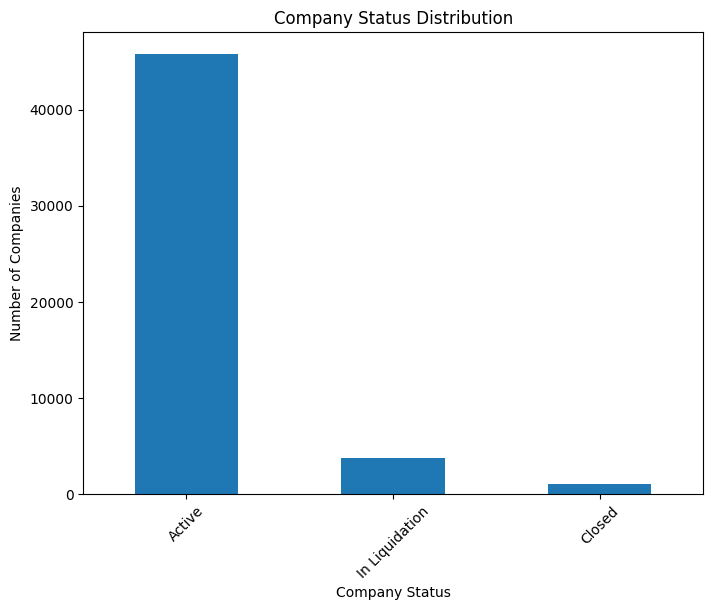

In [ ]:
plt.figure(figsize=(8, 6))
hor["CompanyStatus"].value_counts().plot(kind="bar")
plt.title("Company Status Distribution")
plt.xlabel("Company Status")
plt.ylabel("Number of Companies")

#plt.xticks(rotation=45)
plt.show()

### Company Category

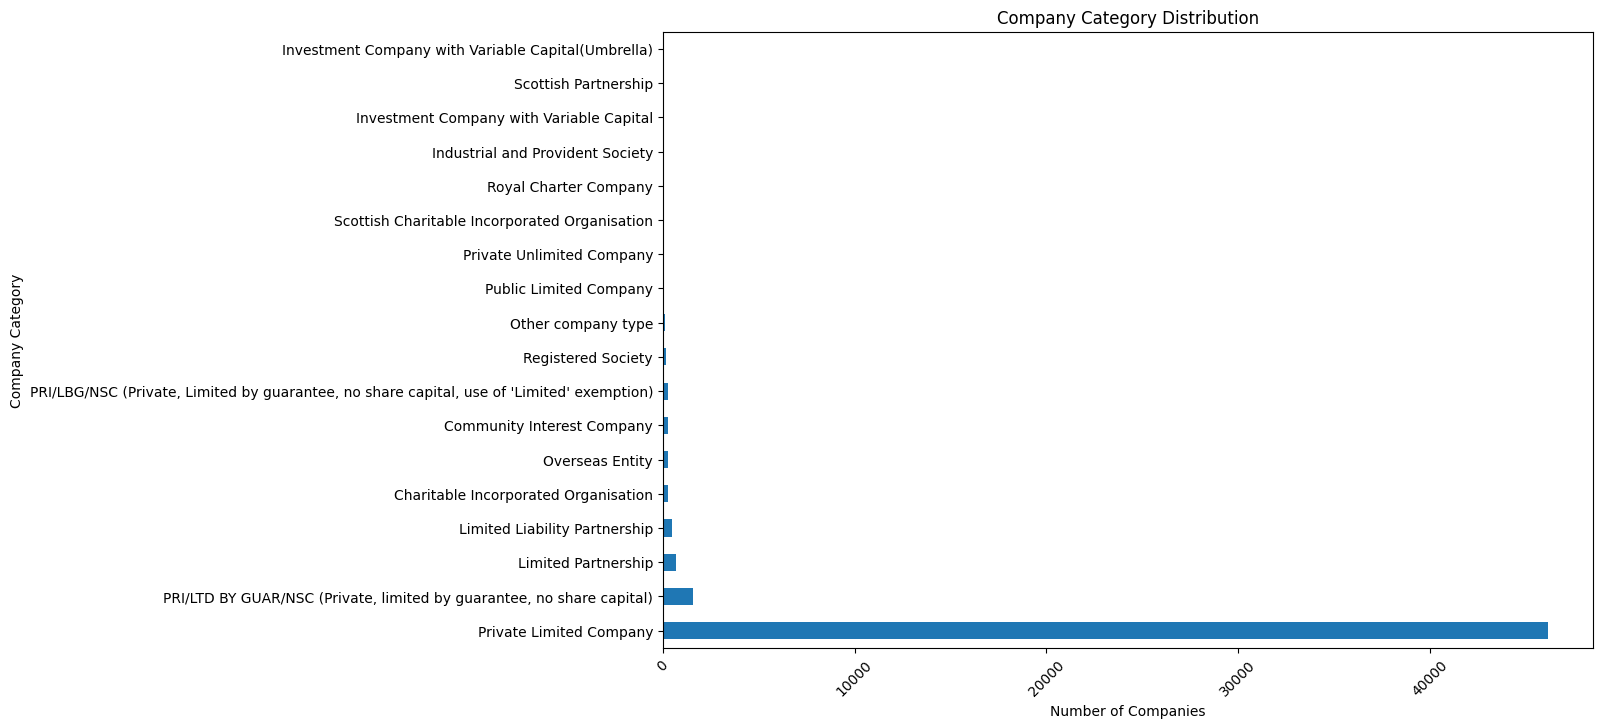

In [ ]:
plt.figure(figsize=(12, 8))
hor["CompanyCategory"].value_counts().plot(kind="barh")
plt.title("Company Category Distribution")
plt.xlabel("Number of Companies")
plt.ylabel("Company Category")

plt.xticks(rotation=45)
plt.show()

### Company Type

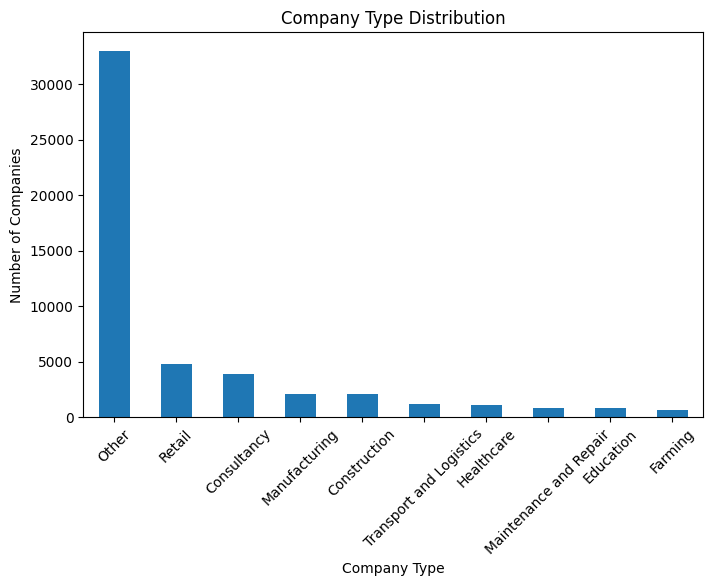

In [ ]:
plt.figure(figsize=(8, 5))
hor["Company Type"].value_counts().plot(kind="bar")
plt.title("Company Type Distribution")
plt.xlabel("Company Type")
plt.ylabel("Number of Companies")

plt.xticks(rotation=45)
plt.show()

### Top 15 countries of origin

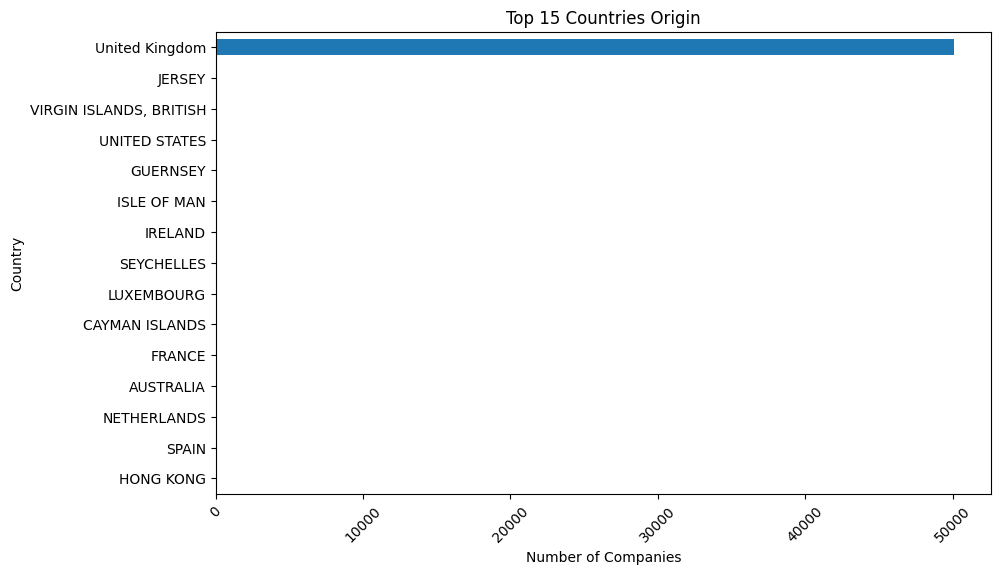

In [ ]:
country_count = hor["CountryOfOrigin"].value_counts().head(15).sort_values()

plt.figure(figsize=(10, 6))
country_count.plot(kind="barh")
plt.title("Top 15 Countries Origin")
plt.xlabel("Number of Companies")
plt.ylabel("Country")

plt.xticks(rotation=45)
plt.show()

### Incorporation Trend

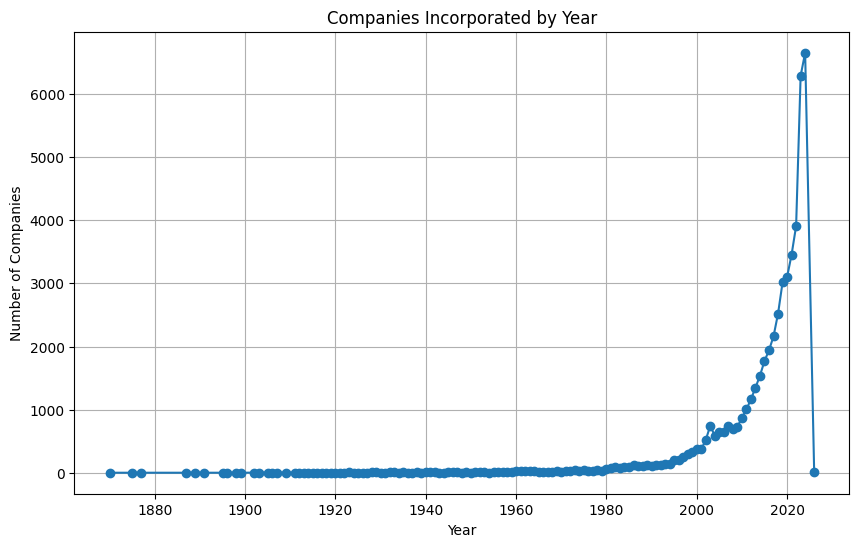

In [ ]:
inc_trend = hor["IncorporationYear"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
inc_trend.plot(kind="line", marker = "o")
plt.title("Companies Incorporated by Year")
plt.xlabel("Year")
plt.ylabel("Number of Companies")

plt.grid(True)
plt.show()

# Which sector has the highest average turnover per company

In [ ]:
sector_turnV = (
    hor.groupby("Company Type")["AverageTurnover"]
    .mean()
    .sort_values(ascending=False)
)

sector_turnV

,AverageTurnover
Company Type,
Construction,3.168612e+06
Consultancy,1.762683e+06
Healthcare,1.094806e+06
Manufacturing,1.078527e+06
Transport and Logistics,1.077419e+06
Maintenance and Repair,6.248681e+05
Retail,6.180538e+05
Farming,4.696895e+05
Education,4.027289e+05


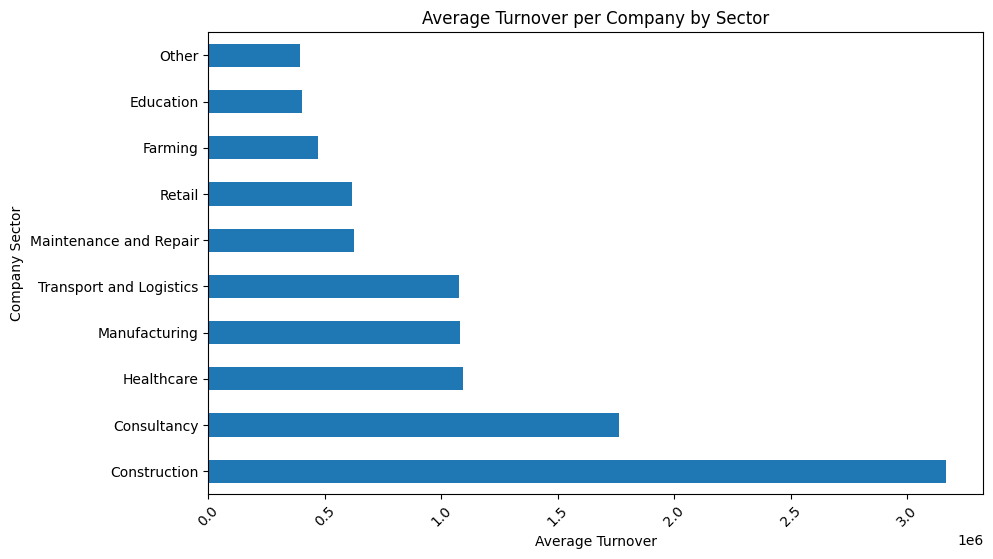

In [ ]:
#Plot

plt.figure(figsize=(10,6))
sector_turnV.plot(kind="barh")
plt.title("Average Turnover per Company by Sector")
plt.xlabel("Average Turnover")
plt.ylabel("Company Sector")

plt.xticks(rotation=45)
plt.show()

#### Number of Companies by Sector

In [ ]:
sect_count = (
    hor["Company Type"]
    .value_counts()
)

sect_count

,count
Company Type,
Other,33026
Retail,4775
Consultancy,3930
Manufacturing,2089
Construction,2058
Transport and Logistics,1160
Healthcare,1127
Maintenance and Repair,846
Education,826


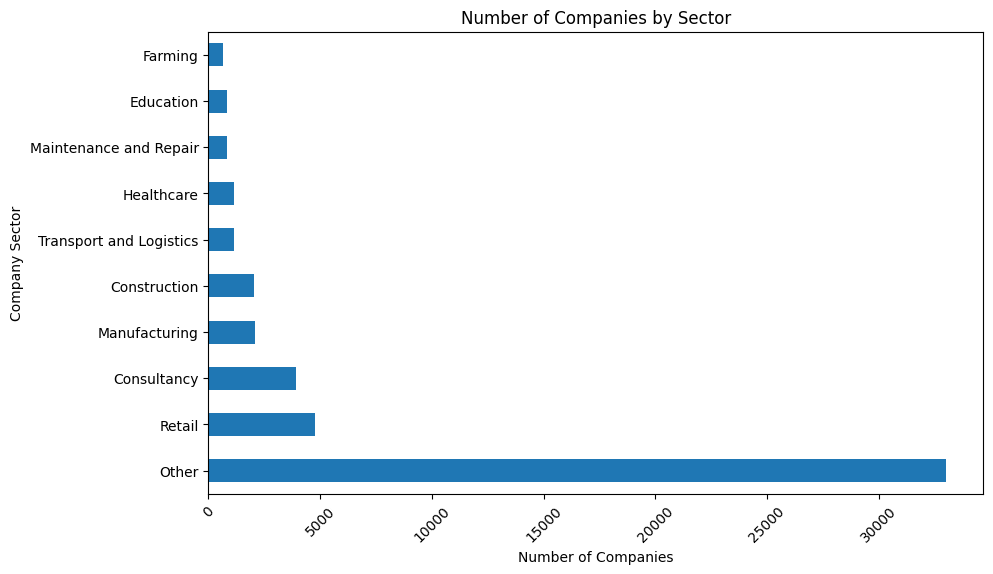

In [ ]:
#plot
plt.figure(figsize=(10,6))
sect_count.plot(kind="barh")
plt.title("Number of Companies by Sector")
plt.xlabel("Number of Companies")
plt.ylabel("Company Sector")

plt.xticks(rotation=45)

plt.show()

## comparison Table

In [ ]:
sect_summary = (
    hor.groupby("Company Type")
    .agg(
        Companies=("Company Reference", "count"),
        AverageTurnover=("AverageTurnover", "mean")
    )
    .sort_values("AverageTurnover", ascending=False)

)

sect_summary

,Companies,AverageTurnover
Company Type,,
Construction,2058,3.168612e+06
Consultancy,3930,1.762683e+06
Healthcare,1127,1.094806e+06
Manufacturing,2089,1.078527e+06
Transport and Logistics,1160,1.077419e+06
Maintenance and Repair,846,6.248681e+05
Retail,4775,6.180538e+05
Farming,639,4.696895e+05
Education,826,4.027289e+05


In [ ]:
highest_turnv_sector = sect_summary.idxmax()["AverageTurnover"]
highest_turnv_value = sect_summary["AverageTurnover"].max()

print(f"The sector with the highest average turnover is {highest_turnv_sector} with an average turnover of {highest_turnv_value}.")
#

The sector with the highest average turnover is Construction with an average turnover of 3168611.606088683.


In [ ]:
largest_sect = sect_summary.idxmax()["Companies"]
largest_sect_value = sect_summary["Companies"].max()

print(f"The sector with the largest number of companies is {largest_sect} with a number of companies of {largest_sect_value}.")
#
#

The sector with the largest number of companies is Other with a number of companies of 33026.


Construction has the highest average turnover per company at approximately £3.17 million. However, Other has by far the largest number of companies, with 33,026 registrations. Therefore, the sector with most companies is not the sector with the highest average turnover.

In [ ]:
#

#2.	What is the most common month for a business to incorporate, and is this consistent across different sectors

### overall most common month

In [ ]:
month_counts = (
    hor["IncorporationMonthName"]
    .value_counts()
)
month_counts

,count
IncorporationMonthName,
January,5101
November,4657
September,4564
April,4482
July,4444
October,4343
May,4275
February,4267
June,4209


In [ ]:
#Putting months in order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month_counts = (
    hor["IncorporationMonthName"]
    .value_counts()
    .reindex(month_order)
)

month_counts

,count
IncorporationMonthName,
January,5101
February,4267
March,4015
April,4482
May,4275
June,4209
July,4444
August,2839
September,4564


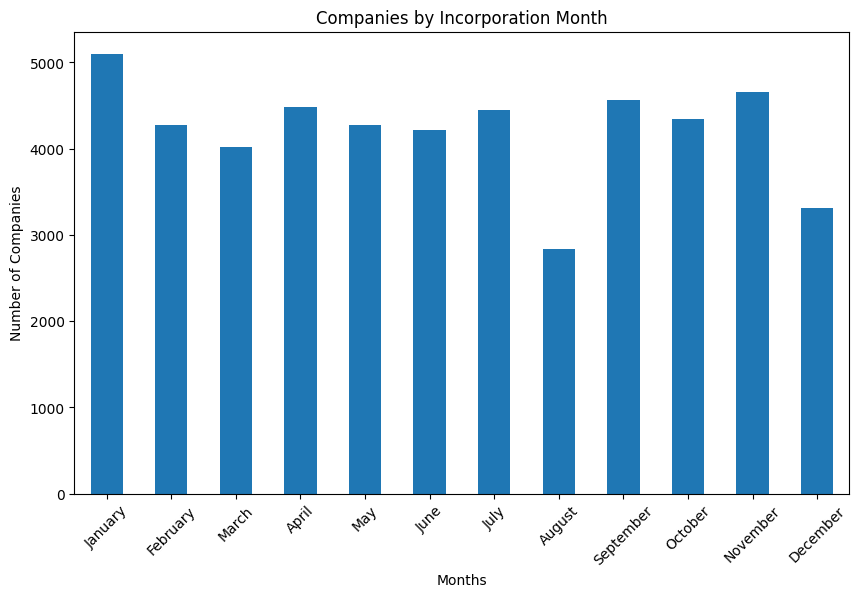

In [ ]:
#Plot

plt.figure(figsize=(10,6))
month_counts.plot(kind="bar")

plt.title("Companies by Incorporation Month")
plt.xlabel("Months")
plt.ylabel("Number of Companies")

plt.xticks(rotation=45)
plt.show()

## Comparing months across sectors

In [ ]:
sect_month = pd.crosstab(
    hor["Company Type"],
    hor["IncorporationMonthName"]
)

sect_month = sect_month.reindex(
    columns=month_order
)

sect_month



IncorporationMonthName,January,February,March,April,May,June,July,August,September,October,November,December
Company Type,,,,,,,,,,,,
Construction,198,195,172,189,168,153,181,124,177,171,199,131
Consultancy,403,325,292,361,347,329,344,241,370,323,364,231
Education,90,79,56,58,60,71,69,53,70,78,70,72
Farming,59,52,41,66,60,61,53,42,51,51,62,41
Healthcare,104,94,89,99,93,93,78,60,120,95,111,91
Maintenance and Repair,79,80,69,68,84,62,84,41,66,75,79,59
Manufacturing,203,155,173,219,190,174,163,115,196,172,196,133
Other,3359,2768,2645,2910,2768,2763,2936,1851,2991,2846,3043,2146
Retail,493,421,379,417,413,399,433,253,412,421,416,318


### Most common month by sector

In [ ]:
most_common_month_by_sect = sect_month.idxmax(axis=1)

print(most_common_month_by_sect)
print("\nNumber of sectors by their most common month:")


Company Type
Construction                November
Consultancy                  January
Education                    January
Farming                        April
Healthcare                 September
Maintenance and Repair           May
Manufacturing                  April
Other                        January
Retail                       January
Transport and Logistics     November
dtype: object

Number of sectors by their most common month:


January is the most common incorporation month overall, with 5,101 companies. The pattern is moderately consistent across sectors, with January being the peak month for half of the sectors, although several sectors show different peak months.

#3.	Which sector shows the most consistent change in turnover year-on-year across the full period, and what does this suggest about that sector’s future performance?

### Turnover Consistency

In [ ]:
#Calculating each Companies growth
hor["Growth_2023"] = (
    (hor["2023 Turnover"] - hor["2022 Turnover"])
    / hor["2022 Turnover"]
) * 100

In [ ]:
hor["Growth_2024"] = (
    (hor["2024 Turnover"] - hor["2023 Turnover"])
    / hor["2023 Turnover"]
 ) * 100


In [ ]:
hor["Growth_2025"] = (
    (hor["2025 Turnover"] - hor["2024 Turnover"])
    / hor["2024 Turnover"]
) * 100


In [ ]:
hor["Growth_2026"] = (
    (hor["2026 Turnover"] - hor["2025 Turnover"])
     / hor["2025 Turnover"]
    )   * 100

### sector growth

In [ ]:
sect_growth = (
    hor.groupby("Company Type")[
        ["Growth_2023", "Growth_2024", "Growth_2025", "Growth_2026"]
    ]
    .mean()
)
sect_growth

,Growth_2023,Growth_2024,Growth_2025,Growth_2026
Company Type,,,,
Construction,0.905211,1.257243,1.980806,0.363170
Consultancy,-28.885999,43.627881,1.682665,1.452191
Education,-10.046604,-12.123137,-14.964353,-15.314675
Farming,4.172571,1.008388,3.474274,0.784726
Healthcare,9.785194,9.959555,10.375612,10.170156
Maintenance and Repair,-9.127061,-12.695098,-15.929886,-17.944002
Manufacturing,-28.654380,44.354415,1.188195,1.739873
Other,-37.186174,1.726476,30.378166,16.976931
Retail,16.930414,-17.775040,17.904999,-19.457847


## sector consistency

In [ ]:
sect_consistency = (
    sect_growth.std(axis=1)
    .sort_values()
)
sect_consistency

,0
Company Type,
Healthcare,0.256070
Construction,0.677883
Farming,1.716135
Transport and Logistics,2.452883
Education,2.493825
Maintenance and Repair,3.860260
Retail,20.819468
Other,29.220234
Consultancy,29.792834


In [ ]:
print("Most consistent sector:", sect_consistency.index[0])
print("Growth variation:", sect_consistency.iloc[0])

Most consistent sector: Healthcare
Growth variation: 0.2560696799271187


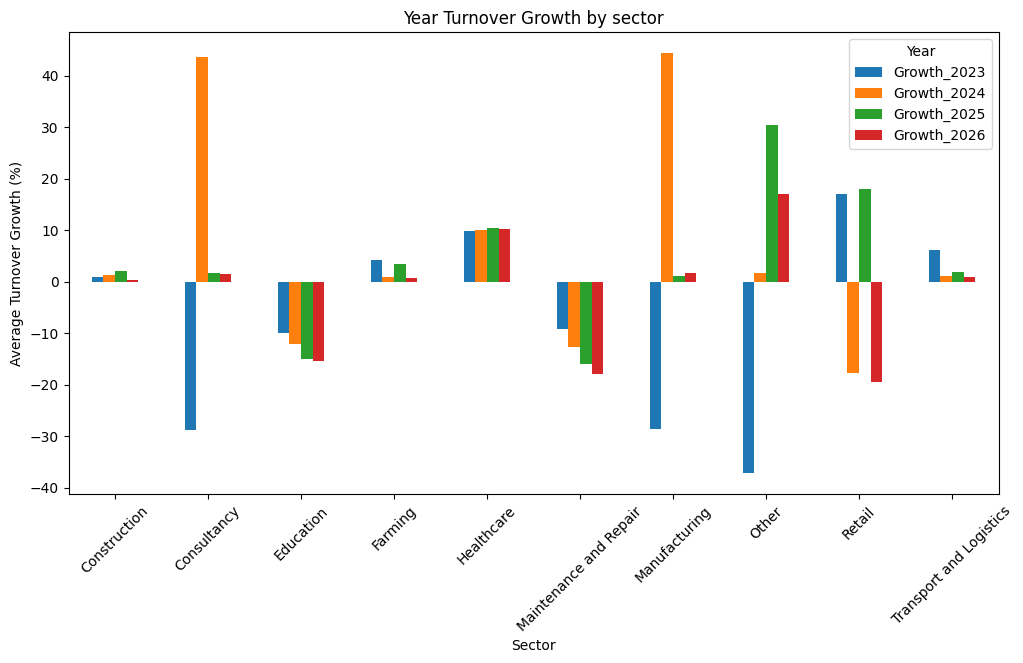

In [ ]:
#plot
sect_growth.plot(
    kind="bar",
    figsize=(12,6)

)

plt.title("Year Turnover Growth by sector")
plt.xlabel("Sector")
plt.ylabel("Average Turnover Growth (%)")

plt.xticks(rotation=45)
plt.legend(title="Year")
plt.show()

Healthcare has the most consistent year-on-year turnover change between 2022 and 2026. Its growth rates were apporoximately 9.8%, 10%, 10.4% and 10.2%, showing very little variation.
This consistency suggests that Healthcare turnover has been relatively predictable based on the historical period. However, historical consistency alone does not guarantee future performance.

#What other conclusions can be drawn from the data. We are particularly interested in trends over time, and comparisons between different geographic areas

### Countries by number of Companies

In [ ]:
Country_count = (
    hor["CountryOfOrigin"]
    .value_counts()
    .head(15)
    .sort_values(ascending=True)
)

Country_count

,count
CountryOfOrigin,
HONG KONG,6
SPAIN,6
NETHERLANDS,6
AUSTRALIA,6
FRANCE,6
CAYMAN ISLANDS,8
LUXEMBOURG,9
SEYCHELLES,10
IRELAND,16


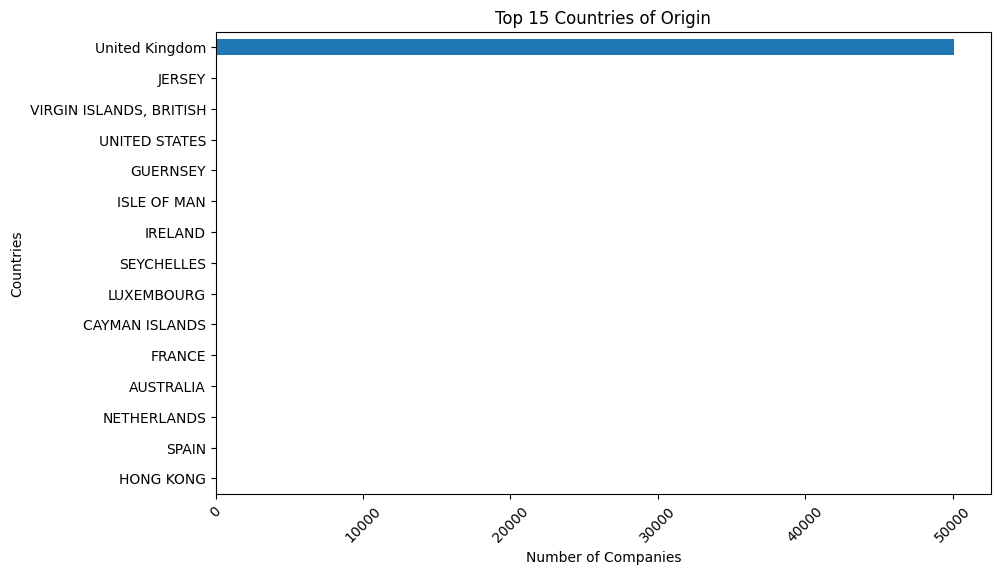

In [ ]:
#Plot
plt.figure(figsize=(10,6))

Country_count.plot(kind="barh")

plt.title("Top 15 Countries of Origin")
plt.xlabel("Number of Companies")
plt.ylabel("Countries")

plt.xticks(rotation=45)
plt.show()

### countries by average turnover

In [ ]:
Country_turnV = (
    hor.groupby("CountryOfOrigin")["AverageTurnover"]
    .mean()
    .dropna()
    .sort_values(ascending=False)
    .head(15)
    .sort_values(ascending=True)
)

Country_turnV


,AverageTurnover
CountryOfOrigin,
PAKISTAN,4.117712e+05
AUSTRALIA,4.197897e+05
NIGERIA,4.334490e+05
CANADA,4.811536e+05
SPAIN,5.063705e+05
United Kingdom,6.979119e+05
UNITED STATES,7.255692e+05
CHANNEL ISLANDS,7.279337e+05
JERSEY,1.001797e+06


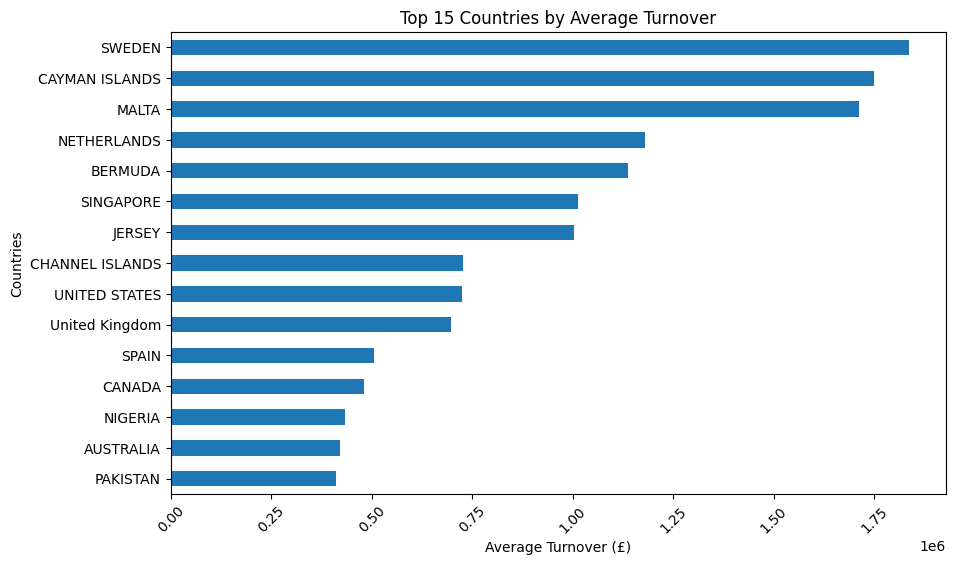

In [ ]:
#Plot
plt.figure(figsize=(10, 6))

Country_turnV.plot(kind="barh")

plt.title("Top 15 Countries by Average Turnover")
plt.xlabel("Average Turnover (£)")
plt.ylabel("Countries")

plt.xticks(rotation=45)
plt.show()

### Incorporation trend over time

In [ ]:
inc_trend = (
    hor["IncorporationYear"]
    .value_counts()
    .sort_index()
)
inc_trend

,count
IncorporationYear,
1870,1
1875,1
1877,1
1887,1
1889,1
...,...
2021,3456
2022,3908
2023,6287


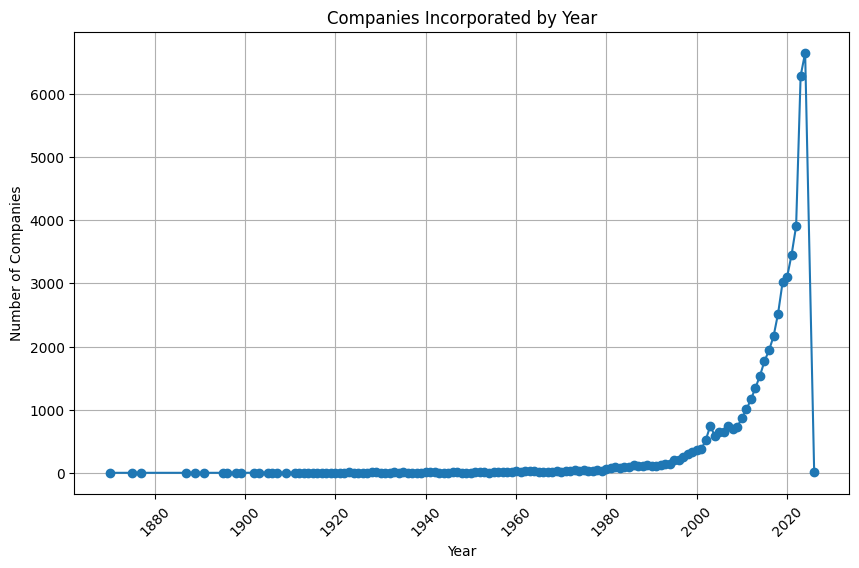

In [ ]:
#Plot
plt.figure(figsize=(10,6))
inc_trend.plot(kind="line", marker="o")

plt.title("Companies Incorporated by Year")
plt.xlabel("Year")
plt.ylabel("Number of Companies")

plt.grid(True)
plt.xticks(rotation=45)
plt.show()


In [ ]:
#Plotting for most recent years
recent_trend = (
    inc_trend[
        inc_trend.index >= 2015
    ]
)


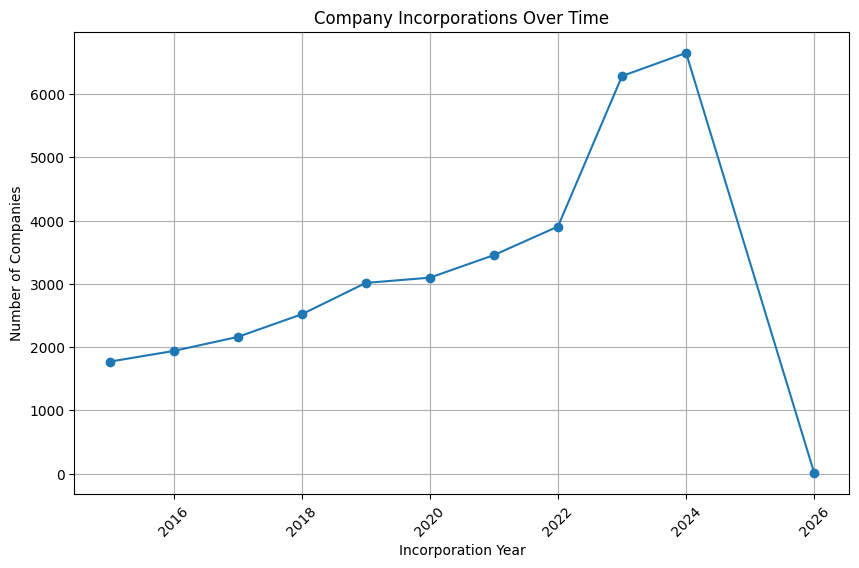

In [ ]:
plt.figure(figsize=(10, 6))

recent_trend.plot(
    kind="line",
    marker="o"
)

plt.title("Company Incorporations Over Time")
plt.xlabel("Incorporation Year")
plt.ylabel("Number of Companies")

plt.grid(True)
plt.xticks(rotation=45)
plt.show()

### Our analysis showsUk, that the dataset is heavily based in the UK, with 50,093 of the 50,501 companies originating from the United Kingdom. However, the UK, does not have the highest average turnover, Sweden does at approximately £1.84 million. This shows that company volume and average turnover are not necessarily aligned geographically. Incorporations also increased from 2021 to 2021, moving from 3456 to 6,653 companies. The low number seen in 2026 incorporations suggest that 2026 is most likely incomplete and should not be interpreted as a genuine decline.